# 04 · Predicting which stops matter (surrogate model)

**The problem:** finding out exactly how much damage closing a stop causes means removing it and recomputing every fastest path in the network. Doing that for all 1,853 LBT stops is the "exhaustive simulation".

**The idea:** train a model on cheap per-stop features (`transitshock.features`) to predict that damage without running the simulation.

**Label:** `efficiency_loss`, the share of network efficiency lost when one stop is removed.

**Build the dataset first** (features plus exhaustive labels, about 1 minute on 10 cores):
```
python -m transitshock.features data/processed/lbt_20261104.gpickle
```

In [1]:
from pathlib import Path

import folium
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupKFold

from transitshock.features import FEATURES
from transitshock.model import MODELS, TARGET, compare, fit, out_of_fold_predictions, score, spatial_groups

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "figures"

df = pd.read_csv(PROCESSED / "lbt_20261104_dataset.csv", index_col="node")
timings = pd.read_csv(PROCESSED / "lbt_20261104_timings.csv", index_col=0)["seconds"]
print(f"{len(df)} stops, {len(FEATURES)} features")
df[FEATURES].describe().T.round(3)

1853 stops, 14 features


,count,mean,std,min,25%,50%,75%,max
trips_per_day,1853.0,49.485,33.558,1.000,29.000,33.000,65.000,327.000
n_routes,1853.0,1.633,1.058,1.000,1.000,1.000,2.000,9.000
transit_in,1853.0,1.074,0.295,0.000,1.000,1.000,1.000,4.000
transit_out,1853.0,1.074,0.300,0.000,1.000,1.000,1.000,4.000
walk_degree,1853.0,2.099,1.456,0.000,1.000,2.000,3.000,10.000
is_terminus,1853.0,0.004,0.066,0.000,0.000,0.000,0.000,1.000
nearest_stop_m,1853.0,66.412,59.750,10.280,35.245,50.886,71.828,568.348
bypass_gap_m,1853.0,711.631,1228.249,0.000,484.921,637.374,807.682,37148.730
stranded_share,1853.0,0.000,0.002,0.000,0.000,0.000,0.000,0.020
betweenness,1853.0,0.015,0.013,0.000,0.005,0.011,0.020,0.094


## 1. What does the ground truth look like?

Removing a stop always loses its own pairs (0.108% of all pairs).
211 of 1853 stops (11%) also cut OTHER stops off from each other.


,efficiency_loss,reachable_loss,added_min
count,1853.00000,1853.00000,1853.00000
mean,0.00241,0.00144,0.03207
std,0.00110,0.00142,0.05641
min,0.00021,0.00108,-0.44659
25%,0.00166,0.00108,0.00989
50%,0.00218,0.00108,0.02445
75%,0.00290,0.00108,0.05275
max,0.01013,0.01600,0.42587


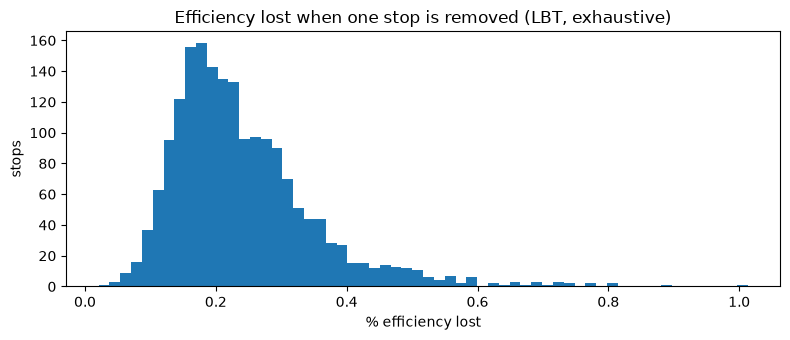

In [2]:
n = len(df)
own_pairs = 2 / n  # share of pairs every removal loses just by deleting the stop itself
cuts_others = df["reachable_loss"] > own_pairs + 1e-9
print(f"Removing a stop always loses its own pairs ({own_pairs:.3%} of all pairs).")
print(f"{cuts_others.sum()} of {n} stops ({cuts_others.mean():.0%}) also cut OTHER stops off from each other.")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(df[TARGET] * 100, bins=60)
ax.set(title="Efficiency lost when one stop is removed (LBT, exhaustive)", xlabel="% efficiency lost", ylabel="stops")
fig.tight_layout()
fig.savefig(FIGURES / "lbt_damage_distribution.png", dpi=150)
df[[TARGET, "reachable_loss", "added_min"]].describe().round(5)

In [3]:
cols = ["name", TARGET, "reachable_loss", "betweenness", "trips_per_day", "bypass_gap_m"]
df.nlargest(15, TARGET)[cols].round(4)

,name,efficiency_loss,reachable_loss,betweenness,trips_per_day,bypass_gap_m
node,,,,,,
lbt:1504,223rd and Avalon NW,0.0101,0.0160,0.0338,44.0,549.1586
lbt:0255,Cherry & Wardlow SW,0.0088,0.0011,0.0935,92.0,426.0551
lbt:0256,Cherry & 33rd SW,0.0081,0.0011,0.0763,92.0,789.8760
lbt:4124,Studebaker & Artesia SW,0.0080,0.0133,0.0154,72.0,1358.4296
lbt:1596,Del Amo & Long Beach Blvd NW,0.0077,0.0011,0.0530,65.0,449.7801
lbt:4101,Studebaker & Artesia NE,0.0077,0.0133,0.0123,34.0,1349.2782
lbt:1506,223rd and Grace NW,0.0074,0.0128,0.0118,44.0,792.4244
lbt:1597,Del Amo & Daisy NW,0.0074,0.0011,0.0471,65.0,1560.4203
lbt:4102,Studebaker & Spinnaker SE,0.0072,0.0128,0.0117,34.0,813.1057


In [4]:
# Map: stop color and size by damage. Saved to figures/lbt_damage_map.html.
m = folium.Map(location=[df["lat"].mean(), df["lon"].mean()], zoom_start=12)
top = df[TARGET].quantile(0.95)
for node, r in df.sort_values(TARGET).iterrows():
    critical = r[TARGET] >= top
    folium.CircleMarker(
        [r["lat"], r["lon"]], radius=6 if critical else 2,
        color="#D62028" if critical else "#555555", fill=True, fill_opacity=0.8, weight=0,
        popup=f"{r['name']}: {r[TARGET]:.3%} efficiency lost",
    ).add_to(m)
m.save(FIGURES / "lbt_damage_map.html")
print("red = top 5% most damaging stops")

red = top 5% most damaging stops


## 2. Heuristics vs. trained models

Every model is scored on stops it **never saw during training** (5-fold cross-validation). There are two ways to split:
- **Random folds:** stops are shuffled into folds. This is optimistic, because a stop's next-door neighbor (with nearly identical features) is often in the training set.
- **Spatial folds:** stops are clustered into 10 neighborhoods, and each fold holds out whole neighborhoods. This is the honest test of whether the model works on a part of the city it hasn't seen.

Scores:
- **R²:** how close the predicted values are to the true ones.
- **Spearman ρ:** how well the predicted ranking matches the true ranking.
- **Top-5% overlap:** of the 93 truly most damaging stops, how many the model also puts in its top 93.

In [5]:
%%time
groups = spatial_groups(df, n_groups=10)
results = pd.concat({
    "random folds": compare(df),
    "spatial folds": compare(df, groups=groups),
}, axis=1).round(3)
results

CPU times: user 1min 43s, sys: 1min 10s, total: 2min 53s
Wall time: 19.6 s


random folds                       spatial folds  \
                                    r2 spearman top5_overlap            r2   
heuristic: betweenness             NaN    0.796        0.473           NaN   
heuristic: trips_per_day           NaN   -0.018        0.032           NaN   
heuristic: n_routes                NaN    0.009        0.022           NaN   
heuristic: harmonic_in             NaN    0.505        0.215           NaN   
heuristic: bypass_gap_m            NaN    0.154        0.108           NaN   
heuristic: stranded_share          NaN    0.176        0.323           NaN   
model: ridge                     0.534    0.867        0.581      -410.947   
model: random_forest             0.837    0.922        0.699         0.760   
model: gradient_boosting         0.834    0.932        0.677         0.730   

                                                 
                          spearman top5_overlap  
heuristic: betweenness       0.796        0.473  
heuristic: trips_per_day    -0.018        0.032  
heuristic: n_routes          0.009        0.022  
heuristic: harmonic_in       0.505        0.215  
heuristic: bypass_gap_m      0.154        0.108  
heuristic: stranded_share    0.176        0.323  
model: ridge                 0.833        0.548  
model: random_forest         0.879        0.645  
model: gradient_boosting     0.875        0.581

## 3. How close are the predictions? (random forest, spatial folds)

r2              0.760
spearman        0.879
top5_overlap    0.645
dtype: float64

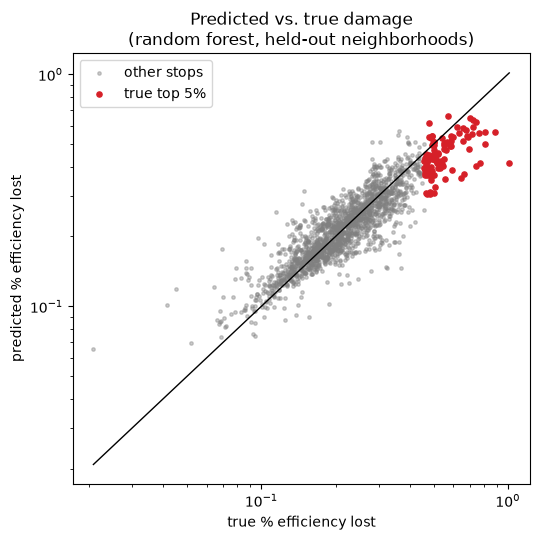

In [6]:
pred = out_of_fold_predictions(df, MODELS["random_forest"], groups=groups)
df["predicted"] = pred

fig, ax = plt.subplots(figsize=(5.5, 5.5))
critical = df[TARGET] >= df[TARGET].quantile(0.95)
ax.scatter(df.loc[~critical, TARGET] * 100, df.loc[~critical, "predicted"] * 100, s=6, alpha=0.4, color="gray", label="other stops")
ax.scatter(df.loc[critical, TARGET] * 100, df.loc[critical, "predicted"] * 100, s=14, color="#D62028", label="true top 5%")
lims = [df[[TARGET, "predicted"]].min().min() * 100, df[[TARGET, "predicted"]].max().max() * 100]
ax.plot(lims, lims, color="black", lw=1)
ax.set(xscale="log", yscale="log", xlabel="true % efficiency lost", ylabel="predicted % efficiency lost",
       title="Predicted vs. true damage\n(random forest, held-out neighborhoods)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "lbt_predicted_vs_true.png", dpi=150)
pd.Series(score(df[TARGET], pred)).round(3)

### Which kinds of critical stops does it find?

The true top 5% splits into two kinds:
- **Cut-off stops:** closing them strands other stops entirely (`reachable_loss` above the 2/n every removal loses).
- **Slow-down stops:** closing them only makes trips longer.

The `stranded_share` feature (dominator trees) was added to catch the first kind. This table compares the model with and without it.

In [7]:
def found_by_kind(df, pred):
    k = int(round(0.05 * len(df)))
    true_top = df.nlargest(k, TARGET)
    found = true_top.index.isin(df.index[np.argsort(-pred)[:k]])
    cuts = (true_top["reachable_loss"] > 2 / len(df) + 1e-9).to_numpy()
    return pd.Series({
        "cut-off stops found": f"{(found & cuts).sum()} / {cuts.sum()}",
        "slow-down stops found": f"{(found & ~cuts).sum()} / {(~cuts).sum()}",
        "total found": f"{found.sum()} / {k}",
    })

without = [f for f in FEATURES if f != "stranded_share"]
pred_without = out_of_fold_predictions(df, MODELS["random_forest"], groups=groups, features=without)
pd.DataFrame({
    "without stranded_share": {**score(df[TARGET], pred_without), **found_by_kind(df, pred_without)},
    "with stranded_share": {**score(df[TARGET], pred), **found_by_kind(df, pred)},
}).T

,r2,spearman,top5_overlap,cut-off stops found,slow-down stops found,total found
without stranded_share,0.58938,0.810997,0.505376,11 / 39,36 / 54,47 / 93
with stranded_share,0.760439,0.87898,0.645161,30 / 39,30 / 54,60 / 93


## 4. Which features does the model rely on?

**Permutation importance:** shuffle one feature in the held-out stops and measure how much worse the predictions get. A big drop means the model depends on that feature. This is computed on held-out neighborhoods, so it reflects what generalizes.

CPU times: user 26.1 s, sys: 4.3 s, total: 30.4 s
Wall time: 19.8 s


betweenness       1.260
stranded_share    0.330
dist_center_km    0.024
harmonic_in       0.020
harmonic_out      0.015
bypass_gap_m      0.010
trips_per_day     0.009
pagerank          0.006
walk_degree       0.002
transit_in        0.000
n_routes          0.000
is_terminus      -0.000
transit_out      -0.000
nearest_stop_m   -0.003
dtype: float64

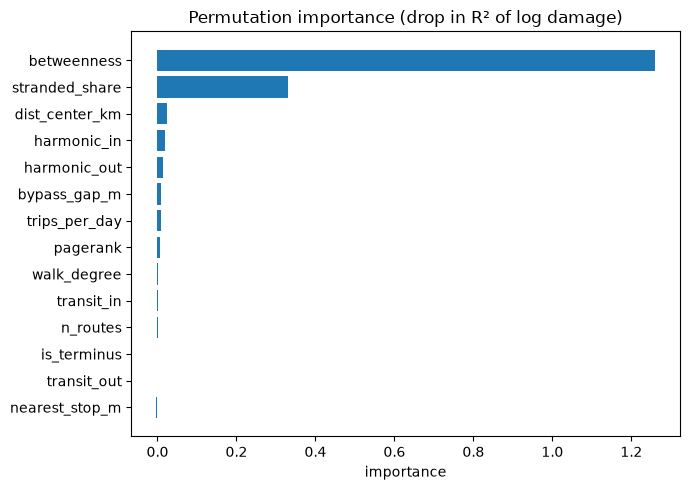

In [8]:
%%time
X, y = df[FEATURES].to_numpy(), np.log(df[TARGET].to_numpy())
importances = []
for train, test in GroupKFold(5).split(X, y, groups):
    model = clone(MODELS["random_forest"]).fit(X[train], y[train])
    r = permutation_importance(model, X[test], y[test], n_repeats=10, random_state=0, scoring="r2")
    importances.append(r.importances_mean)
importance = pd.Series(np.mean(importances, axis=0), index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(importance.index, importance.values, color="#1f77b4")
ax.set(title="Permutation importance (drop in R² of log damage)", xlabel="importance")
fig.tight_layout()
fig.savefig(FIGURES / "lbt_feature_importance.png", dpi=150)
importance.sort_values(ascending=False).round(3)

## 5. Is it actually faster?

Exhaustive simulation: one full network evaluation per stop. Surrogate: compute the features once, then run the model.

*Wall* time is how long you wait. *CPU* time is the total work, roughly what it would take on one core.

In [9]:
final = fit(df)
import time
t = time.perf_counter()
_ = np.exp(final.predict(df[FEATURES].to_numpy()))
predict_s = time.perf_counter() - t

speed = pd.DataFrame({
    "exhaustive simulation": [timings["labels_wall_s"], timings["labels_cpu_s"]],
    "surrogate (features + predict)": [timings["features_wall_s"] + predict_s, timings["features_cpu_s"] + predict_s],
}, index=["wall seconds (10 cores for simulation)", "CPU seconds"]).round(2)
speed["speedup"] = (speed["exhaustive simulation"] / speed["surrogate (features + predict)"]).round(1)
speed

,exhaustive simulation,surrogate (features + predict),speedup
wall seconds (10 cores for simulation),63.29,9.07,7.0
CPU seconds,572.60,9.03,63.4


## 6. The top 20 critical stops: truth vs. model

In [10]:
top_true = df.nlargest(20, TARGET)
top_pred = df.nlargest(20, "predicted")
pd.DataFrame({
    "true rank: stop": top_true["name"].to_numpy(),
    "true % lost": (top_true[TARGET] * 100).round(2).to_numpy(),
    "model rank: stop": top_pred["name"].to_numpy(),
    "in true top 20?": top_pred.index.isin(top_true.index),
}, index=range(1, 21))

,true rank: stop,true % lost,model rank: stop,in true top 20?
1,223rd and Avalon NW,1.01,Wardlow Station Bay 3,False
2,Cherry & Wardlow SW,0.88,Cherry & Spring NE,True
3,Cherry & 33rd SW,0.81,223rd & Grace SE,True
4,Studebaker & Artesia SW,0.80,223rd and Grace NW,True
5,Del Amo & Long Beach Blvd NW,0.77,Del Amo & Norwalk SE,False
6,Studebaker & Artesia NE,0.77,Studebaker & 166th NW,False
7,223rd and Grace NW,0.74,Studebaker & Spinnaker SE,True
8,Del Amo & Daisy NW,0.74,223rd and Dolores SW,True
9,Studebaker & Spinnaker SE,0.72,223rd and Dolores NW,True
10,223rd & Grace SE,0.72,Cherry & PCH SW,False


## Findings

**Ground truth:**
- Removing a single LBT stop costs between 0.02% and 1.0% of network efficiency (median 0.22%).
- Only 211 stops (11%) cut other stops off from each other. Every other removal just slows trips down.
- The most damaging stops are on 223rd St (Avalon/Grace/Dolores), Studebaker near Artesia, the Cherry Ave corridor, and Del Amo Blvd.
- None of them are the busy stops (CSULB, downtown).

**Results on held-out neighborhoods (spatial cross-validation, the honest test):**

| Method | R² | Spearman ρ | Top-5% found |
|---|---|---|---|
| trips/day alone | — | −0.02 | 3% |
| betweenness alone | — | 0.80 | 47% |
| random forest, without `stranded_share` | 0.59 | 0.81 | 51% |
| gradient boosting | 0.73 | 0.88 | 58% |
| **random forest** | **0.76** | **0.88** | **65%** |

**The `stranded_share` feature closed the biggest gap.** The first version of the model found only 11 of the 39 critical stops that *cut other stops off*. Those are stops on one-way loops and branch ends where nothing else reaches the downstream stops.

`stranded_share` measures this directly with **dominator trees**, a classic compiler algorithm. From a starting stop r, stop v *dominates* stop x if every path from r to x goes through v, so closing v strands exactly the stops it dominates. Using every stop as a start, this reproduces the simulation's stranding numbers **exactly** (a unit test checks it). Sampling 200 starts estimates it in about 2 s.

| Random forest, spatial folds | Cut-off stops found | Slow-down stops found | Top 5% total | Top 20 |
|---|---|---|---|---|
| without `stranded_share` | 11 / 39 | 36 / 54 | 47 / 93 | 6 / 20 |
| with `stranded_share` | **30 / 39** | 30 / 54 | **60 / 93** | **11 / 20** |

The slow-down group dropped slightly, from 36 to 30. With a fixed top-93 list, some slots shifted from slow-down to cut-off stops, but the total rose from 47 to 60.

**Other observations:**
- **Two features carry the model.** Permutation importance: betweenness (1.26) predicts the slow-down damage, `stranded_share` (0.33) predicts the cut-off damage, and everything else is under 0.03. Trips/day, the "busy stop" intuition, carries essentially no information about damage.
- **Random folds are misleadingly optimistic.** Random forest scores ρ 0.92 and finds 70% of critical stops on random folds, versus 0.88 and 65% on spatial folds. Report the spatial numbers.
- **Ridge fails on unseen neighborhoods.** Its R² is very negative there, because the linear model extrapolates in log space. The tree models are safer.

**Speed:** the surrogate (features plus prediction) takes about 9 s, versus 573 CPU-seconds for the exhaustive simulation. That's **63× less compute**, or 7× faster in wall time when the simulation runs on all 10 cores.

**Summary:** the model now clearly beats the best single heuristic on held-out neighborhoods (ρ 0.88 vs 0.80; 65% vs 47% of critical stops found). The improvement came from looking at *which* critical stops it missed, then designing a feature from graph theory to capture exactly that.

**Next step:** test whether a model trained on LBT transfers to Metro bus, a different agency with about 6× more stops. That's where a surrogate is most useful, since exhaustive simulation there costs roughly 40× more.